In [ ]:
!pip install -r requirements.txt
!python train.py --help

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 26.6 MB/s eta 0:00:00
usage: train.py [-h] [--epochs EPOCHS] [--patches PATCHES]
                [--batch-size BATCH_SIZE] [--seed SEED] [--out OUT]

options:
  -h, --help            show this help message and exit
  --epochs EPOCHS
  --patches PATCHES
  --batch-size BATCH_SIZE
  --seed SEED
  --out OUT


In [ ]:
!python train.py --epochs 20 --patches 50 --batch-size 32 --seed 42 --out results

{'epoch': 1, 'generator_loss': 6.985971689224243, 'discriminator_loss': 1.0075070261955261}
{'epoch': 2, 'generator_loss': 7.015943765640259, 'discriminator_loss': 0.5675718635320663}
{'epoch': 3, 'generator_loss': 7.237910032272339, 'discriminator_loss': 0.1923833042383194}
{'epoch': 4, 'generator_loss': 8.265282392501831, 'discriminator_loss': 0.2170349359512329}
{'epoch': 5, 'generator_loss': 7.5289833545684814, 'discriminator_loss': 0.18246714025735855}
{'epoch': 6, 'generator_loss': 7.926980257034302, 'discriminator_loss': 0.11042057350277901}
{'epoch': 7, 'generator_loss': 8.271008491516113, 'discriminator_loss': 0.08442770689725876}
{'epoch': 8, 'generator_loss': 8.563894748687744, 'discriminator_loss': 0.06391530856490135}
{'epoch': 9, 'generator_loss': 8.498382329940796, 'discriminator_loss': 0.06275162845849991}
{'epoch': 10, 'generator_loss': 9.893383026123047, 'discriminator_loss': 0.056271862238645554}
{'epoch': 11, 'generator_loss': 10.719062328338623, 'discriminator_loss

In [ ]:
import os
print(os.listdir("results"))

['training_losses.csv', 'generated_epoch_001.png', 'generated_epoch_003.png', 'diagnostics.json', 'generated_epoch_019.png', 'generated_epoch_008.png', 'generated_epoch_014.png', 'generated_epoch_017.png', 'generated_epoch_013.png', 'generated_epoch_016.png', 'generated_epoch_006.png', 'generated_epoch_007.png', 'real_vs_generated.png', 'generated_epoch_002.png', 'generated_epoch_018.png', 'generated_epoch_012.png', 'generated_epoch_009.png', 'generated_epoch_004.png', 'generated_epoch_015.png', 'generated_epoch_011.png', 'generator.pth', 'discriminator.pth', 'generated_epoch_020.png', 'generated_epoch_010.png', 'training_losses.png', 'generated_epoch_005.png']


Generated image files: 20
First epoch:


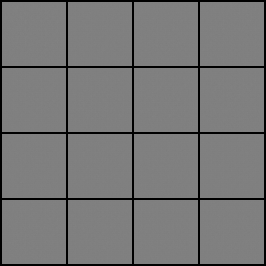

Final saved epoch:


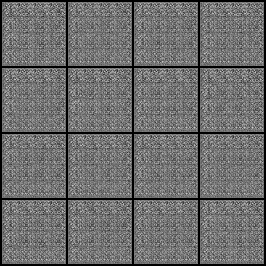

In [ ]:
from IPython.display import display, Image
import glob

images = sorted(glob.glob("results/generated_epoch_*.png"))

print("Generated image files:", len(images))

if images:
    print("First epoch:")
    display(Image(filename=images[0]))

    print("Final saved epoch:")
    display(Image(filename=images[-1]))

   epoch  generator_loss  discriminator_loss
0      1        6.985972            1.007507
1      2        7.015944            0.567572
2      3        7.237910            0.192383
3      4        8.265282            0.217035
4      5        7.528983            0.182467


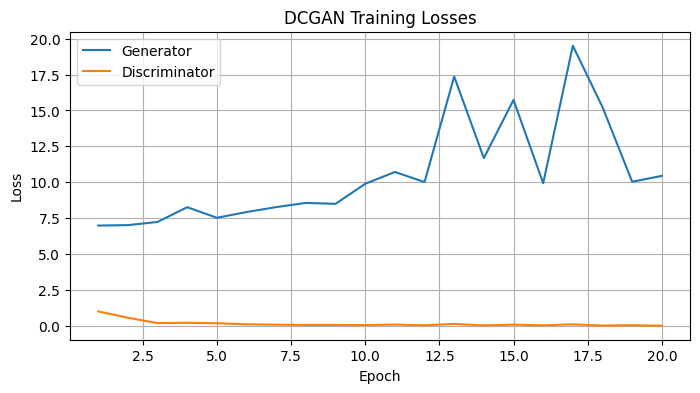

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results/training_losses.csv")

print(df.head())

plt.figure(figsize=(8, 4))
plt.plot(df["epoch"], df["generator_loss"], label="Generator")
plt.plot(df["epoch"], df["discriminator_loss"], label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Losses")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from IPython.display import display, Image
import glob

patches = sorted(glob.glob("**/patch_*.png", recursive=True))

print("Number of patch files:", len(patches))

for path in patches[:5]:
    print(path)
    display(Image(filename=path))

Number of patch files: 0


CT image dimensions: (128, 128)
Minimum pixel value: 128
Maximum pixel value: 2191


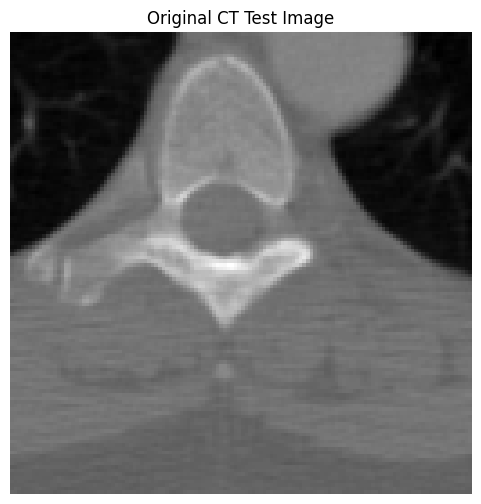

In [ ]:
import pydicom
import matplotlib.pyplot as plt
from pydicom.data import get_testdata_file

path = get_testdata_file("CT_small.dcm")
ds = pydicom.dcmread(path)
ct_image = ds.pixel_array

print("CT image dimensions:", ct_image.shape)
print("Minimum pixel value:", ct_image.min())
print("Maximum pixel value:", ct_image.max())

plt.figure(figsize=(6, 6))
plt.imshow(ct_image, cmap="gray")
plt.title("Original CT Test Image")
plt.axis("off")
plt.show()

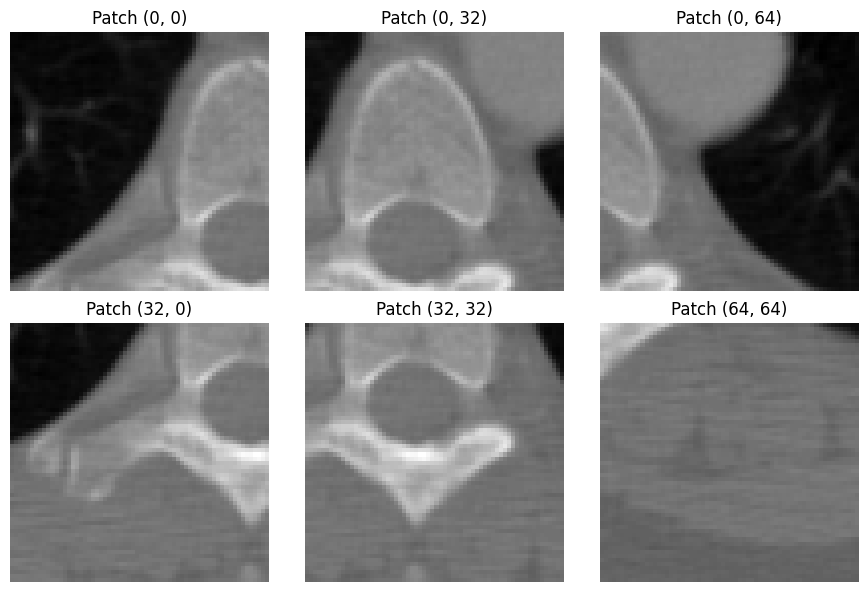

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

ct = ct_image.astype(np.float32)
ct = (ct - ct.min()) / (ct.max() - ct.min())

fig, axes = plt.subplots(2, 3, figsize=(9, 6))

positions = [
    (0, 0), (0, 32), (0, 64),
    (32, 0), (32, 32), (64, 64)
]

for ax, (y, x) in zip(axes.flat, positions):
    patch = ct[y:y+64, x:x+64]
    ax.imshow(patch, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Patch ({y}, {x})")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Currently using CPU")

PyTorch version: 2.11.0+cpu
GPU available: False
Currently using CPU


In [ ]:
import shutil
from google.colab import files

shutil.make_archive("gan_baseline_results", "zip", "results")
files.download("gan_baseline_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [ ]:
import os

print("Current files:", os.listdir("/content"))
print("Training script exists:", os.path.exists("/content/train.py"))
print("Requirements file exists:", os.path.exists("/content/requirements.txt"))

Current files: ['.config', 'sample_data']
Training script exists: False
Requirements file exists: False


In [ ]:
!pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.6 MB/s eta 0:00:00


In [ ]:
with open("train.py", "r") as f:
    code = f.read()

for number, line in enumerate(code.splitlines(), 1):
    if any(word in line.lower() for word in ["cuda", "device", ".to("]):
        print(f"Line {number}: {line}")

Line 70:     if torch.cuda.is_available(): torch.cuda.manual_seed_all(args.seed)
Line 72:     device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
Line 75:     G=Generator().to(device).apply(initialize)
Line 76:     D=Discriminator().to(device).apply(initialize)
Line 80:     fixed_noise=torch.randn(16,100,1,1,device=device)
Line 85:             real=real.to(device); b=real.size(0)
Line 86:             z=torch.randn(b,100,1,1,device=device)
Line 89:             ld=criterion(D(real),torch.ones(b,device=device))+criterion(D(fake.detach()),torch.zeros(b,device=device))
Line 92:             lg=criterion(D(fake),torch.ones(b,device=device))
Line 104:     with torch.no_grad(): fake=G(torch.randn(real.size(0),100,1,1,device=device)).cpu()


In [ ]:
with open("train.py", "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[:70], 1):
    print(f"{i:03d}: {line.rstrip()}")

001: """Reproducible DCGAN baseline on patches from pydicom's CT_small.dcm test image.
002: Research demonstration only: not clinical lung CT data or validated synthesis.
003: """
004: import argparse, csv, json, random
005: from pathlib import Path
006: import numpy as np
007: import pydicom
008: from pydicom.data import get_testdata_file
009: import torch
010: from torch import nn
011: from torch.utils.data import Dataset, DataLoader
012: from torchvision.utils import save_image, make_grid
013: import matplotlib
014: matplotlib.use('Agg')
015: import matplotlib.pyplot as plt
016: 
017: class CTPatches(Dataset):
018:     def __init__(self, count=50, size=64, seed=42):
019:         ds = pydicom.dcmread(get_testdata_file('CT_small.dcm'))
020:         img = ds.pixel_array.astype(np.float32)
021:         img = (img-img.min()) / max(float(img.max()-img.min()), 1e-8)
022:         h,w = img.shape
023:         if min(h,w) < size: raise ValueError('Image smaller than patch size')
024:         

In [ ]:
with open("train.py", "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines[:30], 1):
    print(f"{i:03d}: {line.rstrip()}")

001: """Reproducible DCGAN baseline on patches from pydicom's CT_small.dcm test image.
002: Research demonstration only: not clinical lung CT data or validated synthesis.
003: """
004: import argparse, csv, json, random
005: from pathlib import Path
006: import numpy as np
007: import pydicom
008: from pydicom.data import get_testdata_file
009: import torch
010: from torch import nn
011: from torch.utils.data import Dataset, DataLoader
012: from torchvision.utils import save_image, make_grid
013: import matplotlib
014: matplotlib.use('Agg')
015: import matplotlib.pyplot as plt
016: 
017: class CTPatches(Dataset):
018:     def __init__(self, count=50, size=64, seed=42):
019:         ds = pydicom.dcmread(get_testdata_file('CT_small.dcm'))
020:         img = ds.pixel_array.astype(np.float32)
021:         img = (img-img.min()) / max(float(img.max()-img.min()), 1e-8)
022:         h,w = img.shape
023:         if min(h,w) < size: raise ValueError('Image smaller than patch size')
024:         

In [ ]:
import shutil

shutil.copy("train.py", "train_baseline.py")
print("Baseline script preserved:",
      __import__("os").path.exists("train_baseline.py"))

Baseline script preserved: True


In [ ]:
from google.colab import files

files.download("train_baseline.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

os.makedirs("/content/ct_dataset", exist_ok=True)

print("Dataset folder created successfully")
print("Folder exists:", os.path.isdir("/content/ct_dataset"))

Dataset folder created successfully
Folder exists: True


In [ ]:
from pathlib import Path
import torch

dataset_dir = Path("/content/ct_dataset")

print("Dataset folder exists:", dataset_dir.exists())
if dataset_dir.exists():
    print("Items in folder:", len(list(dataset_dir.iterdir())))

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Dataset folder exists: True
Items in folder: 0
CUDA available: True
GPU: Tesla T4


In [ ]:
from pathlib import Path
import zipfile

zip_path = Path("/content/lidc_idri.zip")
output_dir = Path("/content/ct_dataset")
output_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path) as archive:
    bad_file = archive.testzip()
    if bad_file:
        raise ValueError(f"Damaged ZIP entry: {bad_file}")
    archive.extractall(output_dir)

dcm_files = [
    p for p in output_dir.rglob("*")
    if p.is_file() and p.suffix.lower() == ".dcm"
]

print("DICOM files found:", len(dcm_files))

DICOM files found: 133


In [ ]:
import pydicom
from collections import Counter

headers = [
    pydicom.dcmread(str(path), stop_before_pixels=True)
    for path in dcm_files
]

print("Patients:", sorted({str(ds.PatientID) for ds in headers}))
print("Number of series:", len({str(ds.SeriesInstanceUID) for ds in headers}))
print("Modalities:", dict(Counter(str(ds.Modality) for ds in headers)))

ds = headers[0]
for field in [
    "Rows", "Columns", "PixelSpacing", "SliceThickness",
    "ImageOrientationPatient", "RescaleSlope", "RescaleIntercept",
    "RescaleType", "PhotometricInterpretation"
]:
    print(f"{field}: {getattr(ds, field, 'Missing')}")

Patients: ['LIDC-IDRI-0001']
Number of series: 1
Modalities: {'CT': 133}
Rows: 512
Columns: 512
PixelSpacing: [0.703125, 0.703125]
SliceThickness: 2.500000
ImageOrientationPatient: [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000]
RescaleSlope: 1
RescaleIntercept: -1024
RescaleType: Missing
PhotometricInterpretation: MONOCHROME2


Volume shape: (133, 512, 512)
Slice spacing range (mm): 2.5 2.5


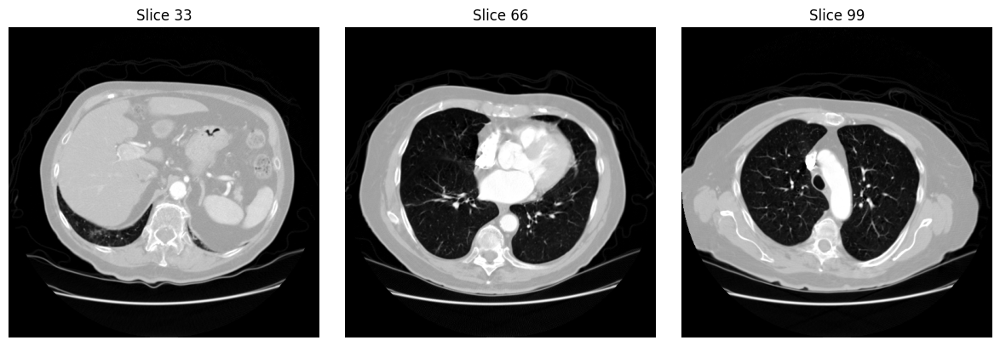

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pydicom

slices = [pydicom.dcmread(str(p)) for p in dcm_files]

orientation = np.asarray(slices[0].ImageOrientationPatient, dtype=float)
normal = np.cross(orientation[:3], orientation[3:])

slices.sort(
    key=lambda ds: float(
        np.dot(np.asarray(ds.ImagePositionPatient, dtype=float), normal)
    )
)

positions = np.array([
    np.dot(np.asarray(ds.ImagePositionPatient, dtype=float), normal)
    for ds in slices
])

volume = np.stack([
    ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope)
    + float(ds.RescaleIntercept)
    for ds in slices
])

print("Volume shape:", volume.shape)
print("Slice spacing range (mm):",
      np.round(np.diff(positions).min(), 4),
      np.round(np.diff(positions).max(), 4))

indices = [len(slices) // 4, len(slices) // 2, 3 * len(slices) // 4]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, index in zip(axes, indices):
    ax.imshow(volume[index], cmap="gray", vmin=-1000, vmax=400)
    ax.set_title(f"Slice {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import zipfile

zip_path = Path("/content/lidc_idri_20patients.zip")
print("ZIP size (MB):", round(zip_path.stat().st_size / 1_000_000, 2))

with zipfile.ZipFile(zip_path) as archive:
    bad_file = archive.testzip()
    print("ZIP integrity:", "OK" if bad_file is None else f"FAILED: {bad_file}")
    print("Files in archive:",
          sum(not item.is_dir() for item in archive.infolist()))

ZIP size (MB): 931.59
ZIP integrity: OK
Files in archive: 3948


In [ ]:
from pathlib import Path
import zipfile

dataset_root = Path("/content/ct_dataset_20patients")
dataset_root.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile("/content/lidc_idri_20patients.zip") as archive:
    archive.extractall(dataset_root)

patient_folders = sorted(
    p.name for p in dataset_root.rglob("LIDC-IDRI-*")
    if p.is_dir() and len(p.name) == len("LIDC-IDRI-0001")
)

print("Patient folders found:", len(patient_folders))
print(patient_folders)
print("Extracted files:",
      sum(p.is_file() for p in dataset_root.rglob("*")))

Patient folders found: 20
['LIDC-IDRI-0001', 'LIDC-IDRI-0002', 'LIDC-IDRI-0003', 'LIDC-IDRI-0004', 'LIDC-IDRI-0005', 'LIDC-IDRI-0006', 'LIDC-IDRI-0007', 'LIDC-IDRI-0008', 'LIDC-IDRI-0009', 'LIDC-IDRI-0010', 'LIDC-IDRI-0011', 'LIDC-IDRI-0012', 'LIDC-IDRI-0013', 'LIDC-IDRI-0014', 'LIDC-IDRI-0015', 'LIDC-IDRI-0016', 'LIDC-IDRI-0017', 'LIDC-IDRI-0018', 'LIDC-IDRI-0019', 'LIDC-IDRI-0020']
Extracted files: 3948


In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import pydicom

dataset_root = Path("/content/ct_dataset_20patients")
modalities = Counter()
ct_series = defaultdict(lambda: defaultdict(list))
read_errors = []

for path in sorted(dataset_root.rglob("*")):
    if not path.is_file() or path.suffix.lower() != ".dcm":
        continue
    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)
        modality = str(getattr(ds, "Modality", "Missing"))
        modalities[modality] += 1

        if modality == "CT":
            patient = str(ds.PatientID)
            series = str(ds.SeriesInstanceUID)
            ct_series[patient][series].append(path)
    except Exception as error:
        read_errors.append((str(path), str(error)))

print("DICOM files by modality:", dict(modalities))
print("Patients with CT:", len(ct_series))
print("Read errors:", len(read_errors))
print("\nPatient | CT series | CT files")

for patient, series_map in sorted(ct_series.items()):
    print(patient, "|", len(series_map), "|",
          sum(len(paths) for paths in series_map.values()))

ModuleNotFoundError: No module named 'pydicom'

In [ ]:
%pip install pydicom==3.0.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 40.1 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import pydicom

dataset_root = Path("/content/ct_dataset_20patients")
modalities = Counter()
ct_series = defaultdict(lambda: defaultdict(list))
read_errors = []

for path in sorted(dataset_root.rglob("*")):
    if not path.is_file() or path.suffix.lower() != ".dcm":
        continue

    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)
        modality = str(getattr(ds, "Modality", "Missing"))
        modalities[modality] += 1

        if modality == "CT":
            patient = str(ds.PatientID)
            series = str(ds.SeriesInstanceUID)
            ct_series[patient][series].append(path)

    except Exception as error:
        read_errors.append((str(path), str(error)))

print("DICOM files by modality:", dict(modalities))
print("Patients with CT:", len(ct_series))
print("Read errors:", len(read_errors))
print("\nPatient | CT series | CT files")

for patient, series_map in sorted(ct_series.items()):
    print(
        patient, "|",
        len(series_map), "|",
        sum(len(paths) for paths in series_map.values())
    )

DICOM files by modality: {'CT': 3592, 'SEG': 178, 'SR': 178}
Patients with CT: 20
Read errors: 0

Patient | CT series | CT files
LIDC-IDRI-0001 | 1 | 133
LIDC-IDRI-0002 | 1 | 261
LIDC-IDRI-0003 | 1 | 140
LIDC-IDRI-0004 | 1 | 241
LIDC-IDRI-0005 | 1 | 133
LIDC-IDRI-0006 | 1 | 133
LIDC-IDRI-0007 | 1 | 145
LIDC-IDRI-0008 | 1 | 133
LIDC-IDRI-0009 | 1 | 256
LIDC-IDRI-0010 | 1 | 277
LIDC-IDRI-0011 | 1 | 128
LIDC-IDRI-0012 | 1 | 128
LIDC-IDRI-0013 | 1 | 125
LIDC-IDRI-0014 | 1 | 114
LIDC-IDRI-0015 | 1 | 209
LIDC-IDRI-0016 | 1 | 141
LIDC-IDRI-0017 | 1 | 238
LIDC-IDRI-0018 | 1 | 127
LIDC-IDRI-0019 | 1 | 305
LIDC-IDRI-0020 | 1 | 225


In [ ]:
print("Patient | Size | Pixel spacing | Slice thickness | Image type")

for patient, series_map in sorted(ct_series.items()):
    for series_uid, paths in series_map.items():
        ds = pydicom.dcmread(str(paths[0]), stop_before_pixels=True)

        print(
            patient,
            "|", f"{getattr(ds, 'Rows', '?')}x{getattr(ds, 'Columns', '?')}",
            "|", str(getattr(ds, "PixelSpacing", "Missing")),
            "|", str(getattr(ds, "SliceThickness", "Missing")),
            "|", str(getattr(ds, "ImageType", "Missing"))
        )

Patient | Size | Pixel spacing | Slice thickness | Image type
LIDC-IDRI-0001 | 512x512 | [0.703125, 0.703125] | 2.500000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0002 | 512x512 | [0.681641, 0.681641] | 1.250000 | ['ORIGINAL', 'SECONDARY', 'AXIAL']
LIDC-IDRI-0003 | 512x512 | [0.820312, 0.820312] | 2.500000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0004 | 512x512 | [0.822266, 0.822266] | 1.250000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0005 | 512x512 | [0.664062, 0.664062] | 2.500000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0006 | 512x512 | [0.625000, 0.625000] | 2.500000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0007 | 512x512 | [0.781250, 0.781250] | 2.500000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0008 | 512x512 | [0.781250, 0.781250] | 2.500000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0009 | 512x512 | [0.781250, 0.781250] | 1.250000 | ['ORIGINAL', 'PRIMARY', 'AXIAL']
LIDC-IDRI-0010 | 512x512 | [0.878906, 0.878906] | 1.250000 | ['DERIVED', 'SECONDARY', 'PRO

In [ ]:
print("Patient | Orientation | Slope | Intercept | Rescale type | Description")

for patient, series_map in sorted(ct_series.items()):
    for paths in series_map.values():
        ds = pydicom.dcmread(str(paths[0]), stop_before_pixels=True)

        print(
            patient,
            "|", str(getattr(ds, "ImageOrientationPatient", "Missing")),
            "|", str(getattr(ds, "RescaleSlope", "Missing")),
            "|", str(getattr(ds, "RescaleIntercept", "Missing")),
            "|", str(getattr(ds, "RescaleType", "Missing")),
            "|", str(getattr(ds, "SeriesDescription", "Missing"))
        )

Patient | Orientation | Slope | Intercept | Rescale type | Description
LIDC-IDRI-0001 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0002 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0003 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0004 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0005 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0006 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0007 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0008 | [1.000000, 0.000000, 0.000000, 0.000000, 1.000000, 0.000000] | 1 | -1024 | Missing | Missing
LIDC-IDRI-0009 | [1.000000, 0.000000, 0.000000, 0

In [ ]:
import numpy as np

print("Patient | Spacing range (mm) | Duplicate positions | Metadata consistent")

for patient, series_map in sorted(ct_series.items()):
    for paths in series_map.values():
        headers = [
            pydicom.dcmread(str(p), stop_before_pixels=True)
            for p in paths
        ]

        try:
            reference = headers[0]
            orientation = np.array(
                reference.ImageOrientationPatient, dtype=float
            )
            normal = np.cross(orientation[:3], orientation[3:])

            positions = np.sort([
                np.dot(np.array(ds.ImagePositionPatient, dtype=float), normal)
                for ds in headers
            ])
            gaps = np.diff(positions)
            duplicates = int(np.sum(gaps < 0.001))

            consistent = all(
                ds.Rows == reference.Rows
                and ds.Columns == reference.Columns
                and np.allclose(
                    ds.ImageOrientationPatient, orientation, atol=1e-5
                )
                and np.allclose(ds.PixelSpacing, reference.PixelSpacing)
                and float(ds.RescaleSlope) == float(reference.RescaleSlope)
                and float(ds.RescaleIntercept) == float(reference.RescaleIntercept)
                for ds in headers
            )

            print(
                patient,
                "|", f"{gaps.min():.4f} to {gaps.max():.4f}",
                "|", duplicates,
                "|", consistent
            )

        except Exception as error:
            print(patient, "| CHECK FAILED:", str(error))

Patient | Spacing range (mm) | Duplicate positions | Metadata consistent
LIDC-IDRI-0001 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0002 | 1.2500 to 1.2500 | 0 | True
LIDC-IDRI-0003 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0004 | 1.2500 to 1.2500 | 0 | True
LIDC-IDRI-0005 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0006 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0007 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0008 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0009 | 1.2500 to 1.2500 | 0 | True
LIDC-IDRI-0010 | 1.2500 to 1.2500 | 0 | True
LIDC-IDRI-0011 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0012 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0013 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0014 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0015 | 1.2500 to 1.2500 | 0 | True
LIDC-IDRI-0016 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0017 | 1.2500 to 1.2500 | 0 | True
LIDC-IDRI-0018 | 2.5000 to 2.5000 | 0 | True
LIDC-IDRI-0019 | 1.2500 to 1.2500 | 0 | True
LIDC-IDRI-0020 | 1.2500 to 1.2500 | 0 | True


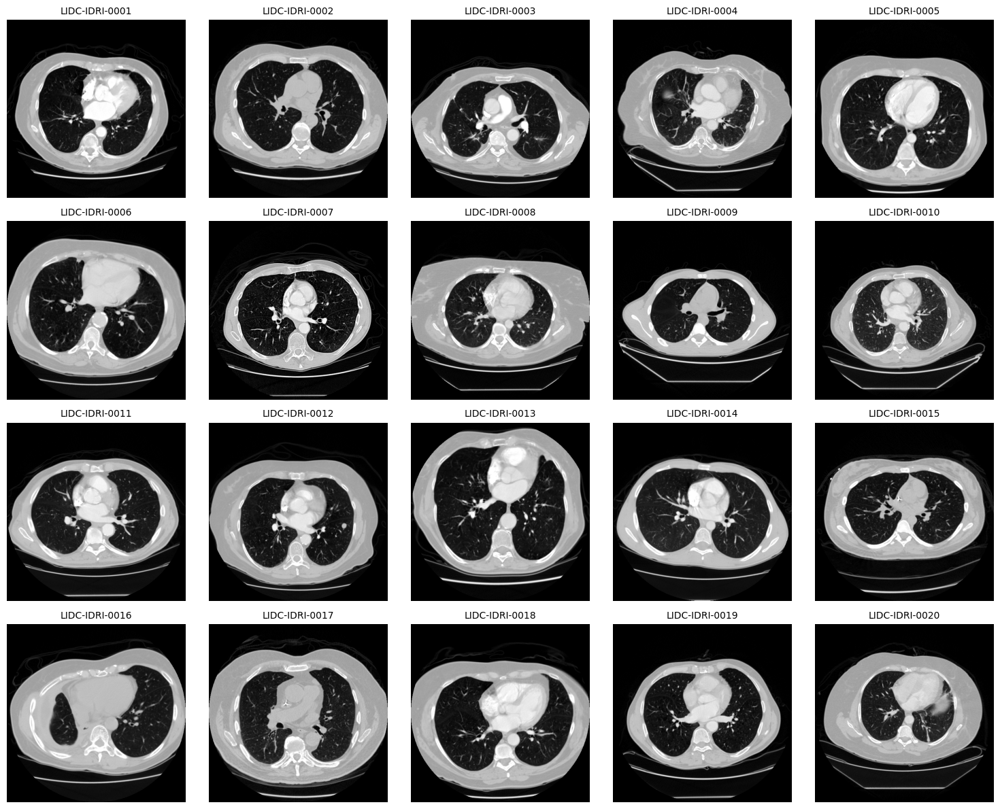

Preview errors: []


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
preview_errors = []

for ax, (patient, series_map) in zip(axes.flat, sorted(ct_series.items())):
    paths = next(iter(series_map.values()))
    headers = [
        pydicom.dcmread(str(p), stop_before_pixels=True)
        for p in paths
    ]

    orientation = np.array(headers[0].ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])

    ordered_paths = sorted(
        zip(paths, headers),
        key=lambda item: np.dot(
            np.array(item[1].ImagePositionPatient, dtype=float), normal
        )
    )

    try:
        middle_path = ordered_paths[len(ordered_paths) // 2][0]
        ds = pydicom.dcmread(str(middle_path))
        image = (
            ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope)
            + float(ds.RescaleIntercept)
        )

        ax.imshow(image, cmap="gray", vmin=-1000, vmax=400)
        ax.set_title(patient, fontsize=10)

    except Exception as error:
        preview_errors.append((patient, str(error)))
        ax.set_title(f"{patient}: decode failed", fontsize=9)

    ax.axis("off")

plt.tight_layout()
plt.show()
print("Preview errors:", preview_errors)

In [ ]:
import random
import json
from pathlib import Path

patients = sorted(ct_series.keys())
assert len(patients) == 20, "Expected 20 patients"

random.Random(42).shuffle(patients)

patient_split = {
    "train": sorted(patients[:14]),
    "validation": sorted(patients[14:17]),
    "test": sorted(patients[17:])
}

assert len(set().union(*map(set, patient_split.values()))) == 20

split_path = Path("/content/patient_split_seed42.json")
split_path.write_text(
    json.dumps({"seed": 42, "splits": patient_split}, indent=2)
)

for split, ids in patient_split.items():
    print(f"\n{split.upper()} ({len(ids)} patients)")
    print(", ".join(ids))

print("\nSaved:", split_path)


TRAIN (14 patients)
LIDC-IDRI-0002, LIDC-IDRI-0005, LIDC-IDRI-0006, LIDC-IDRI-0007, LIDC-IDRI-0010, LIDC-IDRI-0011, LIDC-IDRI-0012, LIDC-IDRI-0013, LIDC-IDRI-0014, LIDC-IDRI-0015, LIDC-IDRI-0016, LIDC-IDRI-0018, LIDC-IDRI-0019, LIDC-IDRI-0020

VALIDATION (3 patients)
LIDC-IDRI-0003, LIDC-IDRI-0008, LIDC-IDRI-0017

TEST (3 patients)
LIDC-IDRI-0001, LIDC-IDRI-0004, LIDC-IDRI-0009

Saved: /content/patient_split_seed42.json


In [ ]:
from google.colab import files
files.download("/content/patient_split_seed42.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
pixel_errors = []
decoded_total = 0

print("Patient | Decoded slices | Rescaled intensity range")

for patient, series_map in sorted(ct_series.items()):
    decoded = 0
    minimum = float("inf")
    maximum = float("-inf")

    for paths in series_map.values():
        for path in paths:
            try:
                ds = pydicom.dcmread(str(path))
                pixels = ds.pixel_array.astype(np.float32)

                if pixels.shape != (int(ds.Rows), int(ds.Columns)):
                    raise ValueError(f"Unexpected pixel shape: {pixels.shape}")

                image = (
                    pixels * float(ds.RescaleSlope)
                    + float(ds.RescaleIntercept)
                )

                if not np.isfinite(image).all():
                    raise ValueError("Non-finite intensities")

                minimum = min(minimum, float(image.min()))
                maximum = max(maximum, float(image.max()))
                decoded += 1

            except Exception as error:
                pixel_errors.append((patient, str(path), str(error)))

    decoded_total += decoded
    print(patient, "|", decoded, "|", minimum, "to", maximum)

print("\nTotal decoded:", decoded_total)
print("Pixel errors:", len(pixel_errors))

for error in pixel_errors[:5]:
    print(error)

Patient | Decoded slices | Rescaled intensity range
LIDC-IDRI-0001 | 133 | -2048.0 to 3071.0
LIDC-IDRI-0002 | 261 | -3024.0 to 1752.0
LIDC-IDRI-0003 | 140 | -2048.0 to 5892.0
LIDC-IDRI-0004 | 241 | -3024.0 to 3071.0
LIDC-IDRI-0005 | 133 | -2048.0 to 3071.0
LIDC-IDRI-0006 | 133 | -2048.0 to 3071.0
LIDC-IDRI-0007 | 145 | -2048.0 to 3071.0
LIDC-IDRI-0008 | 133 | -2048.0 to 3071.0
LIDC-IDRI-0009 | 256 | -3024.0 to 1749.0
LIDC-IDRI-0010 | 277 | -3024.0 to 3071.0
LIDC-IDRI-0011 | 128 | -2048.0 to 3071.0
LIDC-IDRI-0012 | 128 | -2048.0 to 3071.0
LIDC-IDRI-0013 | 125 | -2048.0 to 3071.0
LIDC-IDRI-0014 | 114 | -2048.0 to 3071.0
LIDC-IDRI-0015 | 209 | -3024.0 to 3071.0
LIDC-IDRI-0016 | 141 | -2048.0 to 3071.0
LIDC-IDRI-0017 | 238 | -3024.0 to 2466.0
LIDC-IDRI-0018 | 127 | -2048.0 to 3071.0
LIDC-IDRI-0019 | 305 | -3024.0 to 3071.0
LIDC-IDRI-0020 | 225 | -3024.0 to 3071.0

Total decoded: 3592
Pixel errors: 0


In [ ]:
print("Patient | Photometric | Padding value | Padding limit | SOP class")

for patient, series_map in sorted(ct_series.items()):
    settings = set()

    for paths in series_map.values():
        for path in paths:
            ds = pydicom.dcmread(str(path), stop_before_pixels=True)

            settings.add((
                str(getattr(ds, "PhotometricInterpretation", "Missing")),
                str(getattr(ds, "PixelPaddingValue", "Missing")),
                str(getattr(ds, "PixelPaddingRangeLimit", "Missing")),
                str(getattr(ds, "SOPClassUID", "Missing"))
            ))

    for setting in sorted(settings):
        print(patient, "|", " | ".join(setting))

Patient | Photometric | Padding value | Padding limit | SOP class
LIDC-IDRI-0001 | MONOCHROME2 | 63536 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0002 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0003 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0004 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0005 | MONOCHROME2 | 63536 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0006 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0007 | MONOCHROME2 | 63536 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0008 | MONOCHROME2 | 63536 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0009 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0010 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0011 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0012 | MONOCHROME2 | -2000 | Missing | 1.2.840.10008.5.1.4.1.1.2
LIDC-IDRI-0013 | MONOCHROME2 | 635

In [ ]:
print("Patient | Bits allocated/stored | Signed | Pixel dtype | Padding VR")

for patient, series_map in sorted(ct_series.items()):
    paths = next(iter(series_map.values()))
    ds = pydicom.dcmread(str(paths[0]))

    print(
        patient,
        "|", f"{ds.BitsAllocated}/{ds.BitsStored}",
        "|", ds.PixelRepresentation,
        "|", ds.pixel_array.dtype,
        "|", ds["PixelPaddingValue"].VR
    )

Patient | Bits allocated/stored | Signed | Pixel dtype | Padding VR
LIDC-IDRI-0001 | 16/16 | 1 | int16 | US
LIDC-IDRI-0002 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0003 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0004 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0005 | 16/16 | 1 | int16 | US
LIDC-IDRI-0006 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0007 | 16/16 | 1 | int16 | US
LIDC-IDRI-0008 | 16/16 | 1 | int16 | US
LIDC-IDRI-0009 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0010 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0011 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0012 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0013 | 16/16 | 1 | int16 | US
LIDC-IDRI-0014 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0015 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0016 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0017 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0018 | 16/16 | 1 | int16 | US
LIDC-IDRI-0019 | 16/16 | 1 | int16 | SS
LIDC-IDRI-0020 | 16/16 | 1 | int16 | SS


In [ ]:
def signed_padding_value(value, ds):
    value = int(value)
    bits = int(ds.BitsAllocated)

    if int(ds.PixelRepresentation) == 1 and value >= 2 ** (bits - 1):
        value -= 2 ** bits

    return value


def read_ct_slice(path):
    ds = pydicom.dcmread(str(path))
    pixels = ds.pixel_array
    padding_mask = np.zeros(pixels.shape, dtype=bool)

    if "PixelPaddingValue" in ds:
        padding = signed_padding_value(ds.PixelPaddingValue, ds)

        if "PixelPaddingRangeLimit" in ds:
            limit = signed_padding_value(ds.PixelPaddingRangeLimit, ds)
            low, high = sorted((padding, limit))
            padding_mask = (pixels >= low) & (pixels <= high)
        else:
            padding_mask = pixels == padding

    image = (
        pixels.astype(np.float32) * float(ds.RescaleSlope)
        + float(ds.RescaleIntercept)
    )

    # Keep padding separate from measured image intensities.
    image[padding_mask] = np.nan
    return image, padding_mask, ds


print("CT reader ready. Padding will be masked before preprocessing.")


CT reader ready. Padding will be masked before preprocessing.


Patient: LIDC-IDRI-0002
Masked padding pixels: 55772
Valid intensity range: -1024.0 to 1344.0


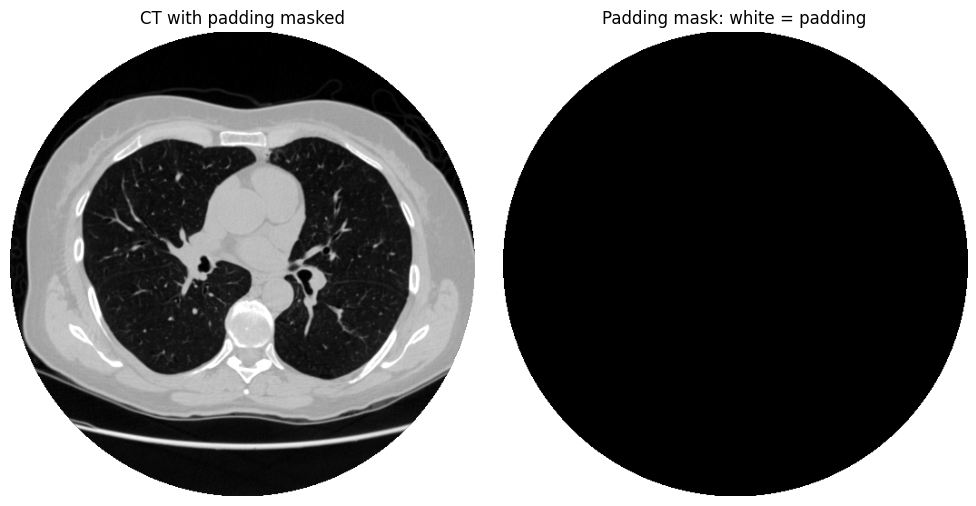

In [ ]:
patient = patient_split["train"][0]
paths = next(iter(ct_series[patient].values()))

def slice_position(path):
    ds = pydicom.dcmread(str(path), stop_before_pixels=True)
    orientation = np.array(ds.ImageOrientationPatient, dtype=float)
    normal = np.cross(orientation[:3], orientation[3:])
    return float(np.dot(ds.ImagePositionPatient, normal))

ordered_paths = sorted(paths, key=slice_position)
middle_path = ordered_paths[len(ordered_paths) // 2]

image, padding_mask, ds = read_ct_slice(middle_path)

print("Patient:", patient)
print("Masked padding pixels:", int(padding_mask.sum()))
print("Valid intensity range:", np.nanmin(image), "to", np.nanmax(image))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image, cmap="gray", vmin=-1000, vmax=400)
axes[0].set_title("CT with padding masked")

axes[1].imshow(padding_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Padding mask: white = padding")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Shape: (512, 512)
Range: -1.0 to 1.0
All values finite: True


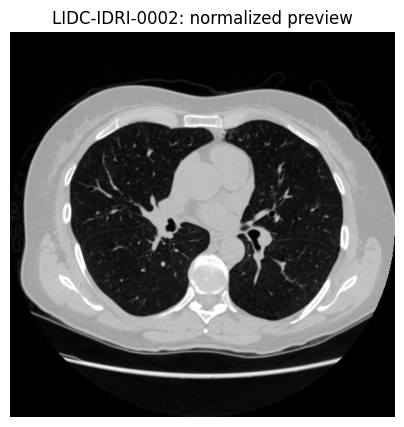

In [ ]:
WINDOW_LOW = -1000.0
WINDOW_HIGH = 400.0

def normalize_ct(image):
    filled = np.where(np.isfinite(image), image, WINDOW_LOW)
    clipped = np.clip(filled, WINDOW_LOW, WINDOW_HIGH)
    normalized = (
        2.0 * (clipped - WINDOW_LOW) / (WINDOW_HIGH - WINDOW_LOW) - 1.0
    )
    return normalized.astype(np.float32)

normalized = normalize_ct(image)

print("Shape:", normalized.shape)
print("Range:", normalized.min(), "to", normalized.max())
print("All values finite:", np.isfinite(normalized).all())

plt.figure(figsize=(5, 5))
plt.imshow(normalized, cmap="gray", vmin=-1, vmax=1)
plt.title(f"{patient}: normalized preview")
plt.axis("off")
plt.show()

Original spacing (mm): ['0.681641', '0.681641']
Target spacing (mm): 1.0
Resampled shape: (349, 349)


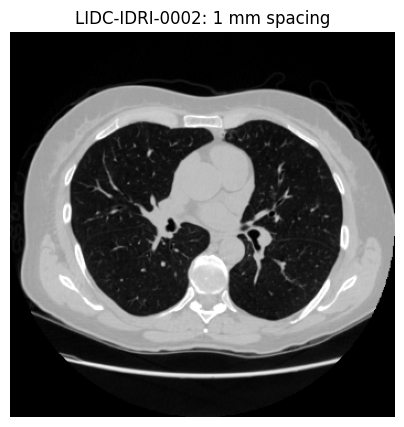

In [ ]:
from scipy.ndimage import zoom

TARGET_SPACING_MM = 1.0

def resample_ct_slice(image, padding_mask, ds):
    spacing = np.array(ds.PixelSpacing, dtype=float)
    factors = spacing / TARGET_SPACING_MM

    filled = np.where(np.isfinite(image), image, WINDOW_LOW)

    resampled = zoom(
        filled, factors, order=1, prefilter=False
    ).astype(np.float32)

    valid_mask = zoom(
        (~padding_mask).astype(np.uint8),
        factors, order=0, prefilter=False
    ).astype(bool)

    resampled[~valid_mask] = np.nan
    return resampled, valid_mask

resampled_image, valid_mask = resample_ct_slice(image, padding_mask, ds)
resampled_normalized = normalize_ct(resampled_image)

print("Original spacing (mm):", list(ds.PixelSpacing))
print("Target spacing (mm):", TARGET_SPACING_MM)
print("Resampled shape:", resampled_image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(resampled_normalized, cmap="gray", vmin=-1, vmax=1)
plt.title(f"{patient}: 1 mm spacing")
plt.axis("off")
plt.show()

Candidate lung-region pixels: 27729


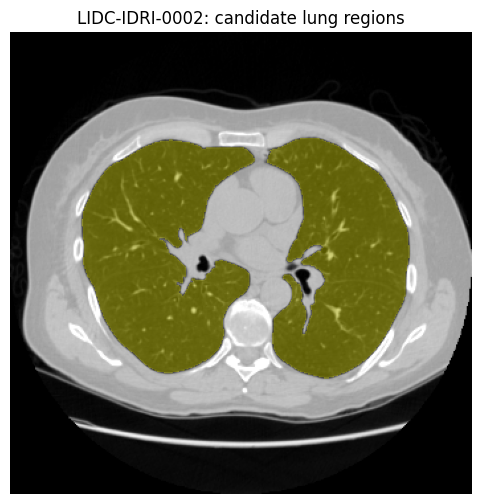

In [ ]:
from scipy import ndimage as ndi

def lung_region_mask(image, valid_mask):
    # Find the largest tissue component and fill its enclosed spaces.
    tissue = valid_mask & np.isfinite(image) & (image > -500)
    labels, count = ndi.label(tissue)

    if count == 0:
        return np.zeros(image.shape, dtype=bool)

    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    body = ndi.binary_fill_holes(labels == sizes.argmax())

    # Find low-density regions inside the body.
    candidates = body & valid_mask & (image < -500)
    labels, count = ndi.label(candidates)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0

    keep = np.flatnonzero(sizes >= 200)
    mask = np.isin(labels, keep)
    return ndi.binary_fill_holes(mask)

lung_mask = lung_region_mask(resampled_image, valid_mask)

print("Candidate lung-region pixels:", int(lung_mask.sum()))

plt.figure(figsize=(6, 6))
plt.imshow(resampled_normalized, cmap="gray", vmin=-1, vmax=1)
plt.imshow(
    np.ma.masked_where(~lung_mask, lung_mask),
    cmap="autumn", alpha=0.35, vmin=0, vmax=1
)
plt.title(f"{patient}: candidate lung regions")
plt.axis("off")
plt.show()

Patches extracted: 8


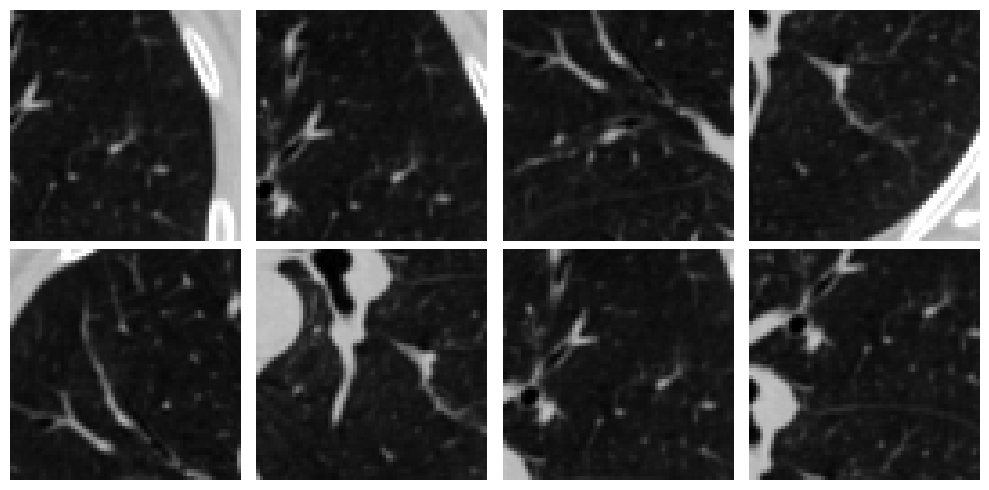

In [ ]:
PATCH_SIZE = 64
rng = np.random.default_rng(42)
preview_patches = []
used_coordinates = set()

height, width = resampled_image.shape

for attempt in range(5000):
    row = int(rng.integers(0, height - PATCH_SIZE + 1))
    col = int(rng.integers(0, width - PATCH_SIZE + 1))

    if (row, col) in used_coordinates:
        continue

    region = np.s_[row:row + PATCH_SIZE, col:col + PATCH_SIZE]

    if not valid_mask[region].all():
        continue
    if lung_mask[region].mean() < 0.80:
        continue

    preview_patches.append(normalize_ct(resampled_image[region]))
    used_coordinates.add((row, col))

    if len(preview_patches) == 8:
        break

print("Patches extracted:", len(preview_patches))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax in axes.flat:
    ax.axis("off")

for ax, patch in zip(axes.flat, preview_patches):
    ax.imshow(patch, cmap="gray", vmin=-1, vmax=1)

plt.tight_layout()
plt.show()

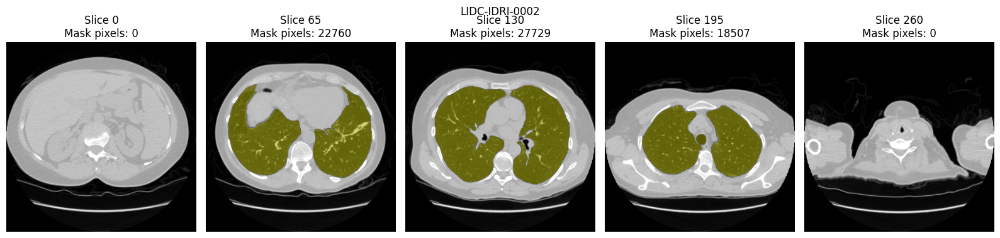

In [ ]:
indices = np.linspace(0, len(ordered_paths) - 1, 5, dtype=int)
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, index in zip(axes, indices):
    slice_image, slice_padding, slice_ds = read_ct_slice(
        ordered_paths[index]
    )
    sampled_image, sampled_valid = resample_ct_slice(
        slice_image, slice_padding, slice_ds
    )
    sampled_mask = lung_region_mask(sampled_image, sampled_valid)

    ax.imshow(normalize_ct(sampled_image), cmap="gray", vmin=-1, vmax=1)
    ax.imshow(
        np.ma.masked_where(~sampled_mask, sampled_mask),
        cmap="autumn", alpha=0.35, vmin=0, vmax=1
    )
    ax.set_title(f"Slice {index}\nMask pixels: {sampled_mask.sum()}")
    ax.axis("off")

plt.suptitle(patient)
plt.tight_layout()
plt.show()

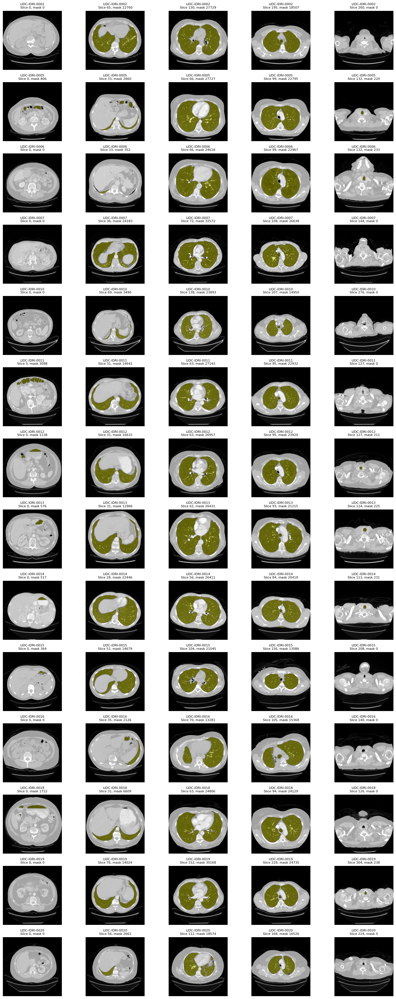

In [ ]:
fig, axes = plt.subplots(14, 5, figsize=(15, 35))

for row, patient_id in enumerate(patient_split["train"]):
    paths = next(iter(ct_series[patient_id].values()))
    sorted_paths = sorted(paths, key=slice_position)
    indices = np.linspace(0, len(sorted_paths) - 1, 5, dtype=int)

    for col, index in enumerate(indices):
        img, padding, metadata = read_ct_slice(sorted_paths[index])
        sampled, valid = resample_ct_slice(img, padding, metadata)
        mask = lung_region_mask(sampled, valid)

        ax = axes[row, col]
        ax.imshow(normalize_ct(sampled), cmap="gray", vmin=-1, vmax=1)
        ax.imshow(
            np.ma.masked_where(~mask, mask),
            cmap="autumn", alpha=0.35, vmin=0, vmax=1
        )
        ax.set_title(
            f"{patient_id}\nSlice {index}, mask {mask.sum()}",
            fontsize=8
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
MIN_LUNG_AREA = 8000
candidate_slices = {}

print("Patient | Candidate slices | First index | Last index")

for patient_id in patient_split["train"]:
    paths = next(iter(ct_series[patient_id].values()))
    sorted_paths = sorted(paths, key=slice_position)
    selected = []

    for index, path in enumerate(sorted_paths):
        img, padding, metadata = read_ct_slice(path)
        sampled, valid = resample_ct_slice(img, padding, metadata)
        mask = lung_region_mask(sampled, valid)

        if int(mask.sum()) >= MIN_LUNG_AREA:
            selected.append((index, path))

    candidate_slices[patient_id] = selected

    print(
        patient_id,
        "|", len(selected),
        "|", selected[0][0] if selected else "None",
        "|", selected[-1][0] if selected else "None"
    )

Patient | Candidate slices | First index | Last index
LIDC-IDRI-0002 | 175 | 43 | 217
LIDC-IDRI-0005 | 80 | 38 | 117
LIDC-IDRI-0006 | 78 | 41 | 118
LIDC-IDRI-0007 | 98 | 32 | 129
LIDC-IDRI-0010 | 144 | 77 | 220
LIDC-IDRI-0011 | 87 | 26 | 112
LIDC-IDRI-0012 | 91 | 23 | 113
LIDC-IDRI-0013 | 86 | 27 | 112
LIDC-IDRI-0014 | 82 | 18 | 99
LIDC-IDRI-0015 | 127 | 44 | 170
LIDC-IDRI-0016 | 76 | 47 | 122
LIDC-IDRI-0018 | 81 | 34 | 114
LIDC-IDRI-0019 | 198 | 67 | 264
LIDC-IDRI-0020 | 114 | 78 | 191


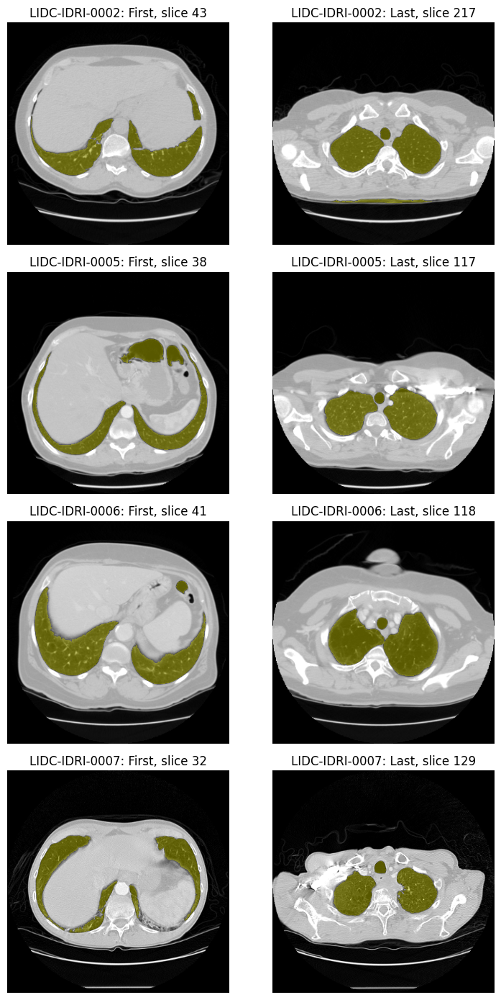

In [ ]:
check_patients = patient_split["train"][:4]
fig, axes = plt.subplots(4, 2, figsize=(8, 14))

for row, patient_id in enumerate(check_patients):
    selected = candidate_slices[patient_id]

    for col, (index, path) in enumerate([selected[0], selected[-1]]):
        img, padding, metadata = read_ct_slice(path)
        sampled, valid = resample_ct_slice(img, padding, metadata)
        mask = lung_region_mask(sampled, valid)

        ax = axes[row, col]
        ax.imshow(normalize_ct(sampled), cmap="gray", vmin=-1, vmax=1)
        ax.imshow(
            np.ma.masked_where(~mask, mask),
            cmap="autumn", alpha=0.35, vmin=0, vmax=1
        )
        boundary = "First" if col == 0 else "Last"
        ax.set_title(f"{patient_id}: {boundary}, slice {index}")
        ax.axis("off")

plt.tight_layout()
plt.show()

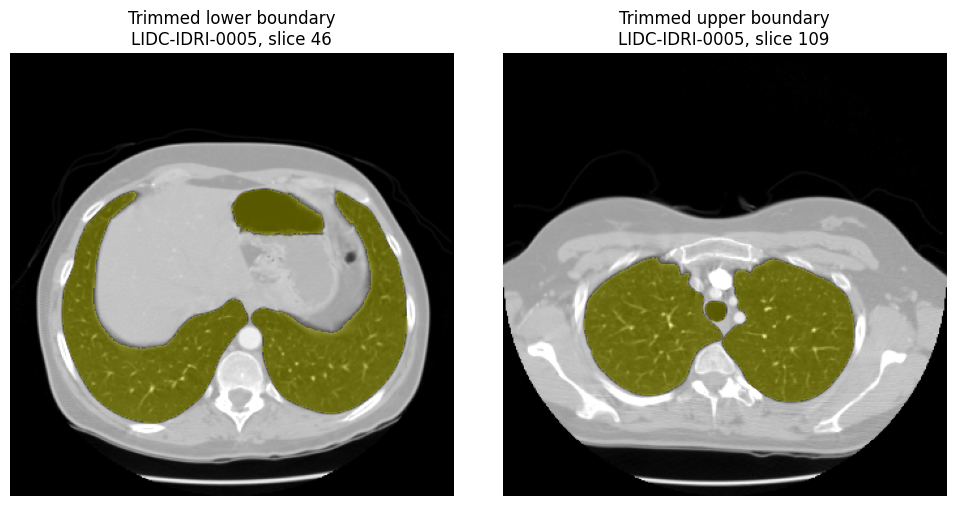

In [ ]:
patient_id = "LIDC-IDRI-0005"
selected = candidate_slices[patient_id]

trim = max(1, int(len(selected) * 0.10))
trimmed = selected[trim:-trim]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (index, path), title in zip(
    axes,
    [trimmed[0], trimmed[-1]],
    ["Trimmed lower boundary", "Trimmed upper boundary"]
):
    img, padding, metadata = read_ct_slice(path)
    sampled, valid = resample_ct_slice(img, padding, metadata)
    mask = lung_region_mask(sampled, valid)

    ax.imshow(normalize_ct(sampled), cmap="gray", vmin=-1, vmax=1)
    ax.imshow(
        np.ma.masked_where(~mask, mask),
        cmap="autumn", alpha=0.35, vmin=0, vmax=1
    )
    ax.set_title(f"{title}\n{patient_id}, slice {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

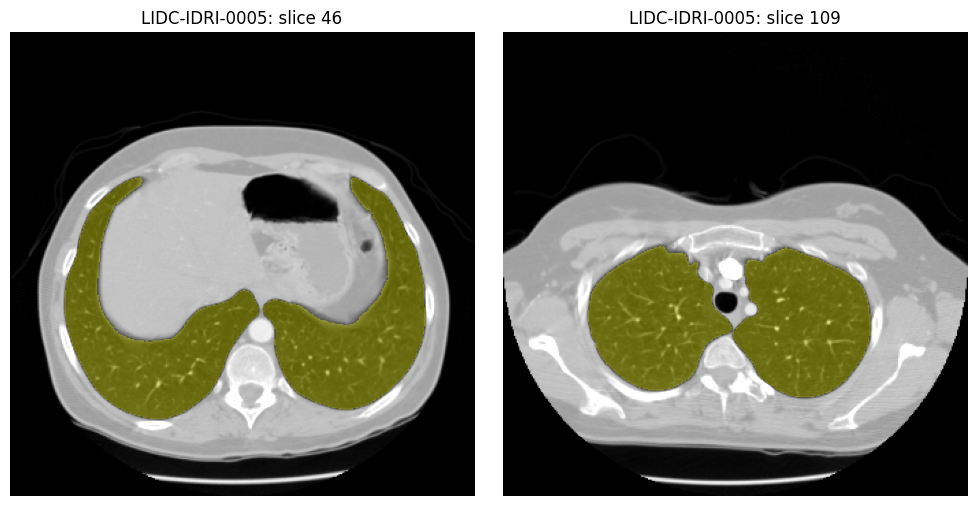

In [ ]:
def keep_two_largest_regions(mask):
    labels, count = ndi.label(mask)

    if count == 0:
        return np.zeros(mask.shape, dtype=bool)

    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    region_ids = np.flatnonzero(sizes > 0)
    largest = region_ids[np.argsort(sizes[region_ids])[-2:]]

    return np.isin(labels, largest)


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (index, path) in zip(axes, [trimmed[0], trimmed[-1]]):
    img, padding, metadata = read_ct_slice(path)
    sampled, valid = resample_ct_slice(img, padding, metadata)

    original_mask = lung_region_mask(sampled, valid)
    cleaned_mask = keep_two_largest_regions(original_mask)

    ax.imshow(normalize_ct(sampled), cmap="gray", vmin=-1, vmax=1)
    ax.imshow(
        np.ma.masked_where(~cleaned_mask, cleaned_mask),
        cmap="autumn", alpha=0.35, vmin=0, vmax=1
    )
    ax.set_title(f"{patient_id}: slice {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

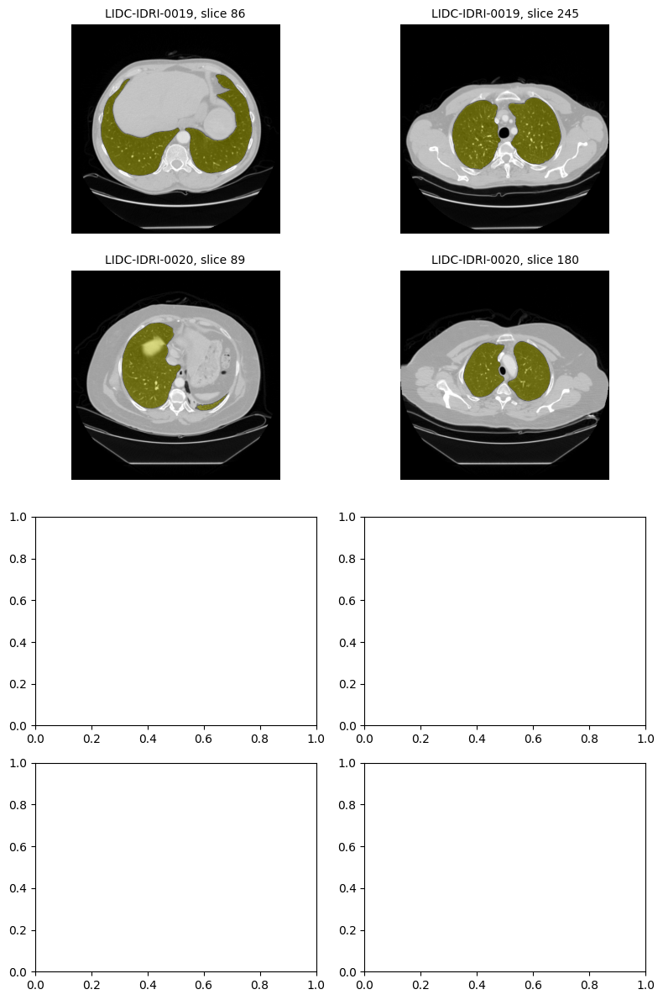

In [ ]:
check_patients = patient_split["train"][12:14]
fig, axes = plt.subplots(4, 2, figsize=(8, 12))

for row, patient_id in enumerate(check_patients):
    selected = candidate_slices[patient_id]
    trim = max(1, int(len(selected) * 0.10))
    trimmed_selection = selected[trim:-trim]

    for col, (index, path) in enumerate(
        [trimmed_selection[0], trimmed_selection[-1]]
    ):
        img, padding, metadata = read_ct_slice(path)
        sampled, valid = resample_ct_slice(img, padding, metadata)
        mask = keep_two_largest_regions(
            lung_region_mask(sampled, valid)
        )

        ax = axes[row, col]
        ax.imshow(normalize_ct(sampled), cmap="gray", vmin=-1, vmax=1)
        ax.imshow(
            np.ma.masked_where(~mask, mask),
            cmap="autumn", alpha=0.35, vmin=0, vmax=1
        )
        ax.set_title(f"{patient_id}, slice {index}", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
training_slice_manifest = []
training_slices = {}

for patient_id in patient_split["train"]:
    selected = candidate_slices[patient_id]
    trim = max(1, int(len(selected) * 0.10))
    kept = selected[trim:-trim]
    training_slices[patient_id] = kept

    for index, path in kept:
        header = pydicom.dcmread(str(path), stop_before_pixels=True)
        training_slice_manifest.append({
            "patient_id": patient_id,
            "series_uid": str(header.SeriesInstanceUID),
            "sop_instance_uid": str(header.SOPInstanceUID),
            "sorted_slice_index": int(index),
            "relative_path": str(path.relative_to(dataset_root))
        })

manifest_path = Path("/content/training_slice_manifest.json")
manifest_path.write_text(json.dumps({
    "minimum_candidate_mask_pixels": 8000,
    "trim_fraction_each_end": 0.10,
    "patch_mask_rule": "keep up to two largest connected regions",
    "slices": training_slice_manifest
}, indent=2))

print("Training patients:", len(training_slices))
print("Selected training slices:", len(training_slice_manifest))
print("Saved:", manifest_path)

Training patients: 14
Selected training slices: 1227
Saved: /content/training_slice_manifest.json


In [ ]:
from google.colab import files
files.download("/content/training_slice_manifest.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def resample_ct_slice(image, padding_mask, ds):
    spacing = np.array(ds.PixelSpacing, dtype=float)
    factors = spacing / TARGET_SPACING_MM

    filled = np.where(np.isfinite(image), image, WINDOW_LOW)

    # Apply smoothing only along dimensions being downsampled.
    sigma = np.maximum((1.0 / factors - 1.0) / 2.0, 0.0)
    smoothed = ndi.gaussian_filter(filled, sigma=sigma)

    resampled = zoom(
        smoothed, factors, order=1, prefilter=False
    ).astype(np.float32)

    # Exclude pixels immediately beside padding.
    safe_valid = ndi.binary_erosion(
        ~padding_mask, iterations=1, border_value=0
    )
    valid_mask = zoom(
        safe_valid.astype(np.uint8),
        factors, order=0, prefilter=False
    ).astype(bool)

    resampled[~valid_mask] = np.nan
    return resampled, valid_mask

print("Updated resampling function ready.")

Updated resampling function ready.


In [ ]:
PATCH_SIZE = 64
MIN_LUNG_FRACTION = 0.80

def extract_slice_patches(path, rng, count=8, max_attempts=5000):
    img, padding, metadata = read_ct_slice(path)
    sampled, valid = resample_ct_slice(img, padding, metadata)
    mask = keep_two_largest_regions(lung_region_mask(sampled, valid))

    height, width = sampled.shape
    patches = []
    coordinates = []
    used = set()

    if min(height, width) < PATCH_SIZE:
        return patches, coordinates

    for _ in range(max_attempts):
        row = int(rng.integers(0, height - PATCH_SIZE + 1))
        col = int(rng.integers(0, width - PATCH_SIZE + 1))

        if (row, col) in used:
            continue

        region = np.s_[row:row + PATCH_SIZE, col:col + PATCH_SIZE]

        if not valid[region].all():
            continue
        if mask[region].mean() < MIN_LUNG_FRACTION:
            continue
        if not np.isfinite(sampled[region]).all():
            continue

        patches.append(normalize_ct(sampled[region]))
        coordinates.append((row, col))
        used.add((row, col))

        if len(patches) >= count:
            break

    return patches, coordinates

print("Patch extractor ready.")

Patch extractor ready.


In [1]:
patient_id = "LIDC-IDRI-0005"
selected = training_slices[patient_id]
index, path = selected[len(selected) // 2]

rng = np.random.default_rng(42)
patches, coordinates = extract_slice_patches(path, rng, count=8)

print("Patient:", patient_id)
print("Slice index:", index)
print("Patches extracted:", len(patches))
print("All patches finite:", all(np.isfinite(p).all() for p in patches))

NameError: name 'training_slices' is not defined

In [2]:
from pathlib import Path

root = Path("/content")

print("Dataset exists:", (root / "ct_dataset_20patients").exists())
print("Dataset ZIP exists:", (root / "lidc_idri_20patients.zip").exists())
print("Manifest exists:", (root / "training_slice_manifest.json").exists())
print("Patient split exists:", (root / "patient_split_seed42.json").exists())
print("Patch extractor defined:", "extract_slice_patches" in globals())

Dataset exists: False
Dataset ZIP exists: False
Manifest exists: False
Patient split exists: False
Patch extractor defined: False


In [4]:
from pathlib import Path
import zipfile
import json
from collections import defaultdict

dataset_root = Path("/content/ct_dataset_20patients")
dataset_root.mkdir(exist_ok=True)

with zipfile.ZipFile("/content/lidc_idri_20patients.zip") as archive:
    archive.extractall(dataset_root)

patient_split = json.loads(
    Path("/content/patient_split_seed42.json").read_text()
)["splits"]

manifest = json.loads(
    Path("/content/training_slice_manifest.json").read_text()
)

training_slices = defaultdict(list)
missing_files = []

for item in manifest["slices"]:
    path = dataset_root / item["relative_path"]
    if not path.is_file():
        missing_files.append(str(path))
    training_slices[item["patient_id"]].append(
        (item["sorted_slice_index"], path)
    )

for selected in training_slices.values():
    selected.sort(key=lambda item: item[0])

print("Restored training patients:", len(training_slices))
print("Restored training slices:", len(manifest["slices"]))
print("Missing files:", len(missing_files))

BadZipFile: File is not a zip file

In [6]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [7]:
from pathlib import Path
import zipfile

zip_path = Path("/content/lidc_idri_20patients.zip")

print("ZIP size (bytes):", zip_path.stat().st_size)
print("Expected size (bytes):", 931586246)

try:
    with zipfile.ZipFile(zip_path) as archive:
        bad_file = archive.testzip()
        print("Archive entries:", len(archive.infolist()))
        print("Integrity:", "OK" if bad_file is None else f"Failed: {bad_file}")
except Exception as error:
    print("ZIP check failed:", str(error))

ZIP size (bytes): 931586246
Expected size (bytes): 931586246
Archive entries: 4365
Integrity: OK


In [8]:
from pathlib import Path
import shutil
import hashlib

backup_dir = Path("/content/drive/MyDrive/ct_gan_project/data")
backup_dir.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

for name in [
    "lidc_idri_20patients.zip",
    "patient_split_seed42.json",
    "training_slice_manifest.json"
]:
    source = Path("/content") / name
    destination = backup_dir / name

    if not destination.exists():
        shutil.copy2(source, destination)

    matches = sha256_file(source) == sha256_file(destination)
    print(name, "| Copy verified:", matches)

print("Drive folder:", backup_dir)

lidc_idri_20patients.zip | Copy verified: True
patient_split_seed42.json | Copy verified: True
training_slice_manifest.json | Copy verified: True
Drive folder: /content/drive/MyDrive/ct_gan_project/data


In [10]:
from pathlib import Path
import zipfile
import json
from collections import defaultdict

In [11]:
from pathlib import Path
import zipfile
import json
from collections import defaultdict

dataset_root = Path("/content/ct_dataset_20patients")
dataset_root.mkdir(exist_ok=True)

with zipfile.ZipFile("/content/lidc_idri_20patients.zip") as archive:
    archive.extractall(dataset_root)

patient_split = json.loads(
    Path("/content/patient_split_seed42.json").read_text()
)["splits"]

manifest = json.loads(
    Path("/content/training_slice_manifest.json").read_text()
)

training_slices = defaultdict(list)
missing_files = []

for item in manifest["slices"]:
    path = dataset_root / item["relative_path"]

    if not path.is_file():
        missing_files.append(str(path))

    training_slices[item["patient_id"]].append(
        (item["sorted_slice_index"], path)
    )

for selected in training_slices.values():
    selected.sort(key=lambda item: item[0])

print("Restored training patients:", len(training_slices))
print("Restored training slices:", len(manifest["slices"]))
print("Missing files:", len(missing_files))

Restored training patients: 14
Restored training slices: 1227
Missing files: 0


In [12]:
%pip install pydicom==3.0.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 55.5 MB/s eta 0:00:00


In [13]:
import numpy as np
import pydicom
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.ndimage import zoom

WINDOW_LOW = -1000.0
WINDOW_HIGH = 400.0
TARGET_SPACING_MM = 1.0
PATCH_SIZE = 64
MIN_LUNG_FRACTION = 0.80

print("pydicom version:", pydicom.__version__)
print("Imports and preprocessing settings ready.")

pydicom version: 3.0.1
Imports and preprocessing settings ready.


In [14]:
def signed_padding_value(value, ds):
    value = int(value)
    bits = int(ds.BitsAllocated)
    if int(ds.PixelRepresentation) == 1 and value >= 2 ** (bits - 1):
        value -= 2 ** bits
    return value


def read_ct_slice(path):
    ds = pydicom.dcmread(str(path))
    pixels = ds.pixel_array
    padding_mask = np.zeros(pixels.shape, dtype=bool)

    if "PixelPaddingValue" in ds:
        padding = signed_padding_value(ds.PixelPaddingValue, ds)

        if "PixelPaddingRangeLimit" in ds:
            limit = signed_padding_value(ds.PixelPaddingRangeLimit, ds)
            low, high = sorted((padding, limit))
            padding_mask = (pixels >= low) & (pixels <= high)
        else:
            padding_mask = pixels == padding

    image = (
        pixels.astype(np.float32) * float(ds.RescaleSlope)
        + float(ds.RescaleIntercept)
    )
    image[padding_mask] = np.nan
    return image, padding_mask, ds


def normalize_ct(image):
    filled = np.where(np.isfinite(image), image, WINDOW_LOW)
    clipped = np.clip(filled, WINDOW_LOW, WINDOW_HIGH)
    return (
        2.0 * (clipped - WINDOW_LOW) / (WINDOW_HIGH - WINDOW_LOW) - 1.0
    ).astype(np.float32)


print("CT reader and normalization restored.")

CT reader and normalization restored.


In [15]:
def resample_ct_slice(image, padding_mask, ds):
    spacing = np.array(ds.PixelSpacing, dtype=float)
    factors = spacing / TARGET_SPACING_MM
    filled = np.where(np.isfinite(image), image, WINDOW_LOW)

    sigma = np.maximum((1.0 / factors - 1.0) / 2.0, 0.0)
    smoothed = ndi.gaussian_filter(filled, sigma=sigma)

    resampled = zoom(
        smoothed, factors, order=1, prefilter=False
    ).astype(np.float32)

    safe_valid = ndi.binary_erosion(
        ~padding_mask, iterations=1, border_value=0
    )
    valid_mask = zoom(
        safe_valid.astype(np.uint8),
        factors, order=0, prefilter=False
    ).astype(bool)

    resampled[~valid_mask] = np.nan
    return resampled, valid_mask


def lung_region_mask(image, valid_mask):
    tissue = valid_mask & np.isfinite(image) & (image > -500)
    labels, count = ndi.label(tissue)

    if count == 0:
        return np.zeros(image.shape, dtype=bool)

    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    body = ndi.binary_fill_holes(labels == sizes.argmax())

    candidates = body & valid_mask & (image < -500)
    labels, count = ndi.label(candidates)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0

    keep = np.flatnonzero(sizes >= 200)
    mask = np.isin(labels, keep)
    return ndi.binary_fill_holes(mask)


def keep_two_largest_regions(mask):
    labels, count = ndi.label(mask)

    if count == 0:
        return np.zeros(mask.shape, dtype=bool)

    sizes = np.bincount(labels.ravel())
    sizes[0] = 0
    region_ids = np.flatnonzero(sizes > 0)
    largest = region_ids[np.argsort(sizes[region_ids])[-2:]]

    return np.isin(labels, largest)


print("Resampling and mask functions restored.")

Resampling and mask functions restored.


In [16]:
def extract_slice_patches(path, rng, count=8, max_attempts=5000):
    img, padding, metadata = read_ct_slice(path)
    sampled, valid = resample_ct_slice(img, padding, metadata)
    mask = keep_two_largest_regions(lung_region_mask(sampled, valid))

    height, width = sampled.shape
    patches, coordinates = [], []
    used = set()

    if min(height, width) < PATCH_SIZE:
        return patches, coordinates

    for _ in range(max_attempts):
        row = int(rng.integers(0, height - PATCH_SIZE + 1))
        col = int(rng.integers(0, width - PATCH_SIZE + 1))

        if (row, col) in used:
            continue

        region = np.s_[row:row + PATCH_SIZE, col:col + PATCH_SIZE]

        if not valid[region].all():
            continue
        if mask[region].mean() < MIN_LUNG_FRACTION:
            continue
        if not np.isfinite(sampled[region]).all():
            continue

        patches.append(normalize_ct(sampled[region]))
        coordinates.append((row, col))
        used.add((row, col))

        if len(patches) >= count:
            break

    return patches, coordinates


patient_id = "LIDC-IDRI-0005"
selected = training_slices[patient_id]
index, path = selected[len(selected) // 2]

patches, coordinates = extract_slice_patches(
    path, np.random.default_rng(42), count=8
)

print("Patient:", patient_id)
print("Slice index:", index)
print("Patches extracted:", len(patches))
print("All patches finite:", all(np.isfinite(p).all() for p in patches))

Patient: LIDC-IDRI-0005
Slice index: 78
Patches extracted: 8
All patches finite: True


In [17]:
import inspect
from pathlib import Path

code_dir = Path("/content/drive/MyDrive/ct_gan_project/code")
code_dir.mkdir(parents=True, exist_ok=True)

function_names = [
    signed_padding_value,
    read_ct_slice,
    normalize_ct,
    resample_ct_slice,
    lung_region_mask,
    keep_two_largest_regions,
    extract_slice_patches
]

source = """import numpy as np
import pydicom
from scipy import ndimage as ndi
from scipy.ndimage import zoom

WINDOW_LOW = -1000.0
WINDOW_HIGH = 400.0
TARGET_SPACING_MM = 1.0
PATCH_SIZE = 64
MIN_LUNG_FRACTION = 0.80

"""

source += "\n\n".join(inspect.getsource(fn) for fn in function_names)

code_path = code_dir / "ct_preprocessing_v1.py"
code_path.write_text(source)

compile(source, str(code_path), "exec")
print("Saved preprocessing code:", code_path)
print("Syntax check passed.")

Saved preprocessing code: /content/drive/MyDrive/ct_gan_project/code/ct_preprocessing_v1.py
Syntax check passed.


In [18]:
output_dir = Path(
    "/content/drive/MyDrive/ct_gan_project/data/training_patches_v1"
)
output_dir.mkdir(parents=True, exist_ok=True)

for patient_id in patient_split["train"]:
    destination = output_dir / f"{patient_id}.npz"

    if destination.exists():
        print(patient_id, "| Already saved, skipped")
        continue

    patient_number = int(patient_id.rsplit("-", 1)[1])
    rng = np.random.default_rng([42, patient_number])

    patient_patches = []
    patch_locations = []
    short_slices = 0

    for index, path in training_slices[patient_id]:
        extracted, coordinates = extract_slice_patches(path, rng, count=8)

        if len(extracted) < 8:
            short_slices += 1

        for patch, (row, col) in zip(extracted, coordinates):
            patient_patches.append(patch)
            patch_locations.append((index, row, col))

    if not patient_patches:
        raise RuntimeError(f"No patches extracted for {patient_id}")

    array = np.stack(patient_patches)[:, None, :, :]
    locations = np.asarray(patch_locations, dtype=np.int32)

    assert np.isfinite(array).all()
    assert array.min() >= -1 and array.max() <= 1

    temporary = output_dir / f"{patient_id}.partial.npz"
    np.savez_compressed(
        temporary,
        patches=array,
        locations=locations,
        patient_id=patient_id,
        seed=42
    )
    temporary.replace(destination)

    print(
        patient_id,
        "| Patches:", len(array),
        "| Slices with fewer than 8 patches:", short_slices,
        flush=True
    )

print("Training patch extraction finished.")

LIDC-IDRI-0002 | Patches: 1128 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0005 | Patches: 512 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0006 | Patches: 512 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0007 | Patches: 640 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0010 | Patches: 928 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0011 | Patches: 568 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0012 | Patches: 584 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0013 | Patches: 560 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0014 | Patches: 528 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0015 | Patches: 824 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0016 | Patches: 496 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0018 | Patches: 520 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0019 | Patches: 1280 | Slices with fewer than 8 patches: 0
LIDC-IDRI-0020 | Patches: 736 | Slices with fewer than 8 patches: 0
Training patch extraction finished.


In [19]:
total = 0

for patient_id in patient_split["train"]:
    path = output_dir / f"{patient_id}.npz"

    with np.load(path, allow_pickle=False) as saved:
        array = saved["patches"]
        locations = saved["locations"]

        assert str(saved["patient_id"].item()) == patient_id
        assert array.shape[1:] == (1, 64, 64)
        assert locations.shape == (len(array), 3)
        assert np.isfinite(array).all()
        assert array.min() >= -1 and array.max() <= 1
        assert len(np.unique(locations, axis=0)) == len(locations)

        total += len(array)
        print(patient_id, "| Verified:", array.shape)

print("\nTotal verified training patches:", total)

LIDC-IDRI-0002 | Verified: (1128, 1, 64, 64)
LIDC-IDRI-0005 | Verified: (512, 1, 64, 64)
LIDC-IDRI-0006 | Verified: (512, 1, 64, 64)
LIDC-IDRI-0007 | Verified: (640, 1, 64, 64)
LIDC-IDRI-0010 | Verified: (928, 1, 64, 64)
LIDC-IDRI-0011 | Verified: (568, 1, 64, 64)
LIDC-IDRI-0012 | Verified: (584, 1, 64, 64)
LIDC-IDRI-0013 | Verified: (560, 1, 64, 64)
LIDC-IDRI-0014 | Verified: (528, 1, 64, 64)
LIDC-IDRI-0015 | Verified: (824, 1, 64, 64)
LIDC-IDRI-0016 | Verified: (496, 1, 64, 64)
LIDC-IDRI-0018 | Verified: (520, 1, 64, 64)
LIDC-IDRI-0019 | Verified: (1280, 1, 64, 64)
LIDC-IDRI-0020 | Verified: (736, 1, 64, 64)

Total verified training patches: 9816


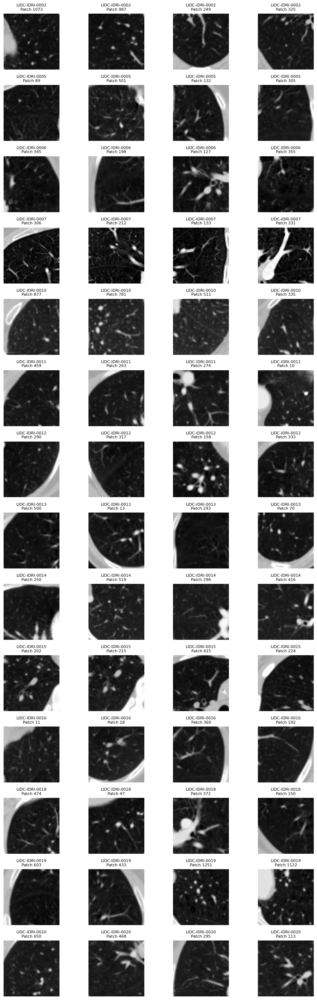

In [20]:
fig, axes = plt.subplots(14, 4, figsize=(10, 28))

for row, patient_id in enumerate(patient_split["train"]):
    with np.load(output_dir / f"{patient_id}.npz", allow_pickle=False) as saved:
        patient_patches = saved["patches"]
        indices = np.random.default_rng(
            [42, int(patient_id.rsplit("-", 1)[1])]
        ).choice(len(patient_patches), size=4, replace=False)

        for col, index in enumerate(indices):
            ax = axes[row, col]
            ax.imshow(
                patient_patches[index, 0],
                cmap="gray", vmin=-1, vmax=1
            )
            ax.set_title(f"{patient_id}\nPatch {index}", fontsize=8)
            ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
validation_ct = defaultdict(list)

for path in sorted(dataset_root.rglob("*.dcm")):
    ds = pydicom.dcmread(str(path), stop_before_pixels=True)

    if (
        str(getattr(ds, "Modality", "")) == "CT"
        and str(ds.PatientID) in patient_split["validation"]
    ):
        orientation = np.array(ds.ImageOrientationPatient, dtype=float)
        normal = np.cross(orientation[:3], orientation[3:])
        position = float(np.dot(ds.ImagePositionPatient, normal))

        validation_ct[str(ds.PatientID)].append((position, path))

for patient_id in patient_split["validation"]:
    validation_ct[patient_id].sort(key=lambda item: item[0])
    print(patient_id, "| CT slices:", len(validation_ct[patient_id]))

LIDC-IDRI-0003 | CT slices: 140
LIDC-IDRI-0008 | CT slices: 133
LIDC-IDRI-0017 | CT slices: 238


In [22]:
validation_dir = Path(
    "/content/drive/MyDrive/ct_gan_project/data/validation_patches_v1"
)
validation_dir.mkdir(parents=True, exist_ok=True)
validation_manifest = []

for patient_id in patient_split["validation"]:
    candidates = []

    for index, (_, path) in enumerate(validation_ct[patient_id]):
        img, padding, metadata = read_ct_slice(path)
        sampled, valid = resample_ct_slice(img, padding, metadata)

        if lung_region_mask(sampled, valid).sum() >= 8000:
            candidates.append((index, path))

    if len(candidates) < 3:
        raise RuntimeError(f"Too few candidate slices: {patient_id}")

    trim = max(1, int(len(candidates) * 0.10))
    selected = candidates[trim:-trim]

    rng = np.random.default_rng([42, int(patient_id.rsplit("-", 1)[1])])
    patches, locations = [], []

    for index, path in selected:
        extracted, coordinates = extract_slice_patches(path, rng, count=8)

        for patch, (row, col) in zip(extracted, coordinates):
            patches.append(patch)
            locations.append((index, row, col))

        validation_manifest.append({
            "patient_id": patient_id,
            "sorted_slice_index": index,
            "relative_path": str(path.relative_to(dataset_root))
        })

    if not patches:
        raise RuntimeError(f"No validation patches: {patient_id}")

    array = np.stack(patches)[:, None, :, :]
    assert np.isfinite(array).all()

    np.savez_compressed(
        validation_dir / f"{patient_id}.npz",
        patches=array,
        locations=np.asarray(locations, dtype=np.int32),
        patient_id=patient_id,
        seed=42
    )

    print(patient_id, "| Selected slices:", len(selected),
          "| Patches:", len(array), flush=True)

(validation_dir / "slice_manifest.json").write_text(
    json.dumps(validation_manifest, indent=2)
)
print("Validation extraction finished.")

LIDC-IDRI-0003 | Selected slices: 75 | Patches: 600
LIDC-IDRI-0008 | Selected slices: 56 | Patches: 448
LIDC-IDRI-0017 | Selected slices: 121 | Patches: 968
Validation extraction finished.


In [23]:
train_ids = set(patient_split["train"])
validation_ids = set(patient_split["validation"])
test_ids = set(patient_split["test"])

assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)

validation_total = 0

for patient_id in patient_split["validation"]:
    with np.load(
        validation_dir / f"{patient_id}.npz", allow_pickle=False
    ) as saved:
        array = saved["patches"]
        locations = saved["locations"]

        assert str(saved["patient_id"].item()) == patient_id
        assert array.shape[1:] == (1, 64, 64)
        assert locations.shape == (len(array), 3)
        assert np.isfinite(array).all()
        assert array.min() >= -1 and array.max() <= 1
        assert len(np.unique(locations, axis=0)) == len(locations)

        validation_total += len(array)
        print(patient_id, "| Verified patches:", len(array))

print("Total validation patches:", validation_total)
print("Patient separation verified.")

LIDC-IDRI-0003 | Verified patches: 600
LIDC-IDRI-0008 | Verified patches: 448
LIDC-IDRI-0017 | Verified patches: 968
Total validation patches: 2016
Patient separation verified.


In [25]:
import torch

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [26]:
from pathlib import Path
import numpy as np
import torch

patch_dir = Path(
    "/content/drive/MyDrive/ct_gan_project/data/training_patches_v1"
)

arrays = []
for patient_id in patient_split["train"]:
    with np.load(patch_dir / f"{patient_id}.npz",
                 allow_pickle=False) as saved:
        arrays.append(saved["patches"])

train_images = torch.from_numpy(np.concatenate(arrays, axis=0))
del arrays

print("Training tensor:", tuple(train_images.shape))
print("Data type:", train_images.dtype)

Training tensor: (9816, 1, 64, 64)
Data type: torch.float32


In [27]:
import random
from torch.utils.data import TensorDataset, DataLoader

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

loader_rng = torch.Generator().manual_seed(seed)

train_loader = DataLoader(
    TensorDataset(train_images),
    batch_size=32,
    shuffle=True,
    drop_last=False,
    num_workers=0,
    pin_memory=True,
    generator=loader_rng,
)

print("Training patches:", len(train_images))
print("Batches per epoch:", len(train_loader))

Training patches: 9816
Batches per epoch: 307


In [28]:
import torch.nn as nn

device = torch.device("cuda")
nz = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(nz, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
        ]
        for incoming, outgoing in [(512, 256), (256, 128), (128, 64)]:
            layers += [
                nn.ConvTranspose2d(incoming, outgoing, 4, 2, 1, bias=False),
                nn.BatchNorm2d(outgoing),
                nn.ReLU(True),
            ]
        layers += [
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),
            nn.Tanh(),
        ]
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
        ]
        for incoming, outgoing in [(64, 128), (128, 256), (256, 512)]:
            layers += [
                nn.Conv2d(incoming, outgoing, 4, 2, 1, bias=False),
                nn.BatchNorm2d(outgoing),
                nn.LeakyReLU(0.2, inplace=True),
            ]
        layers += [nn.Conv2d(512, 1, 4, 1, 0, bias=False)]
        self.net = nn.Sequential(*layers)

    def forward(self, images):
        return self.net(images).view(-1)


def initialize_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


netG = Generator().to(device)
netD = Discriminator().to(device)
netG.apply(initialize_weights)
netD.apply(initialize_weights)

print("Generator and discriminator initialized on", device)

Generator and discriminator initialized on cuda


In [29]:
import json
from datetime import datetime, timezone
from pathlib import Path

criterion = nn.BCEWithLogitsLoss()

optimizerG = torch.optim.Adam(
    netG.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
optimizerD = torch.optim.Adam(
    netD.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

num_epochs = 20
fixed_noise = torch.randn(
    64, nz, 1, 1,
    generator=torch.Generator().manual_seed(42)
).to(device)

assert Path("/content/drive/MyDrive").is_dir(), "Mount Google Drive first."

run_name = datetime.now(timezone.utc).strftime(
    "dcgan_lidc_v1_%Y%m%d_%H%M%S"
)
run_dir = Path("/content/drive/MyDrive/ct_gan_project/runs") / run_name
run_dir.mkdir(parents=True, exist_ok=False)

config = {
    "seed": 42,
    "epochs": num_epochs,
    "batch_size": 32,
    "latent_dimension": nz,
    "learning_rate_G": 0.0002,
    "learning_rate_D": 0.0002,
    "adam_betas": [0.5, 0.999],
    "loss": "BCEWithLogitsLoss",
    "sampling": "uniform over patches, shuffled",
    "training_patches": len(train_images),
    "patient_split": patient_split,
    "patch_directory": str(patch_dir),
    "torch_version": str(torch.__version__),
    "cuda_version": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
}

(run_dir / "config.json").write_text(json.dumps(config, indent=2))
torch.save(fixed_noise.cpu(), run_dir / "fixed_noise.pt")

history = []
start_epoch = 0

print("Settings saved.")
print("Results folder:", run_dir)

Settings saved.
Results folder: /content/drive/MyDrive/ct_gan_project/runs/dcgan_lidc_v1_20261014_174128


In [32]:
import time
import matplotlib.pyplot as plt

# Preserve this cell's code for reproducibility.
(run_dir / "training_loop.py").write_text(In[-1])

for epoch in range(start_epoch, num_epochs)):
    started = time.time()
    netG.train()
    netD.train()
    total_G = total_D = 0.0
    seen = 0

    for (images,) in train_loader:
        real = images.to(device, non_blocking=True)
        batch = len(real)

        # Train discriminator.
        optimizerD.zero_grad(set_to_none=True)
        noise = torch.randn(batch, nz, 1, 1, device=device)
        fake = netG(noise)

        lossD = (
            criterion(netD(real), torch.ones(batch, device=device))
            + criterion(netD(fake.detach()), torch.zeros(batch, device=device))
        )
        if not torch.isfinite(lossD):
            raise RuntimeError("Non-finite discriminator loss")
        lossD.backward()
        optimizerD.step()

        # Train generator, keeping discriminator parameters fixed.
        for parameter in netD.parameters():
            parameter.requires_grad_(False)

        optimizerG.zero_grad(set_to_none=True)
        lossG = criterion(netD(fake), torch.ones(batch, device=device))
        if not torch.isfinite(lossG):
            raise RuntimeError("Non-finite generator loss")
        lossG.backward()
        optimizerG.step()

        for parameter in netD.parameters():
            parameter.requires_grad_(True)

        total_G += lossG.item() * batch
        total_D += lossD.item() * batch
        seen += batch

    record = {
        "epoch": epoch + 1,
        "generator_loss": total_G / seen,
        "discriminator_loss": total_D / seen,
        "seconds": time.time() - started,
    }
    history.append(record)

    # Use fixed noise and a fixed display range.
    netG.eval()
    with torch.no_grad():
        samples = netG(fixed_noise).cpu()

    fig, axes = plt.subplots(8, 8, figsize=(8, 8))
    for ax, sample in zip(axes.flat, samples):
        ax.imshow(sample[0], cmap="gray", vmin=-1, vmax=1)
        ax.axis("off")
    fig.tight_layout(pad=0.1)
    fig.savefig(run_dir / f"samples_epoch_{epoch + 1:03d}.png")
    plt.close(fig)
    netG.train()

    checkpoint = {
        "epoch": epoch + 1,
        "generator": netG.state_dict(),
        "discriminator": netD.state_dict(),
        "optimizerG": optimizerG.state_dict(),
        "optimizerD": optimizerD.state_dict(),
        "fixed_noise": fixed_noise.cpu(),
        "history": history,
        "config": config,
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all(),
        "loader_rng": loader_rng.get_state(),
        "numpy_rng": np.random.get_state(),
        "python_rng": random.getstate(),
    }

    temporary = run_dir / "checkpoint.partial.pt"
    torch.save(checkpoint, temporary)
    temporary.replace(run_dir / "checkpoint_latest.pt")
    (run_dir / "history.json").write_text(json.dumps(history, indent=2))
    start_epoch = epoch + 1

    print(
        f"Epoch {start_epoch}/{num_epochs} | "
        f"G: {record['generator_loss']:.4f} | "
        f"D: {record['discriminator_loss']:.4f} | "
        f"Time: {record['seconds']:.0f}s"
    )
    print("Checkpoint saved to Google Drive.")

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 26)

In [33]:
code = (run_dir / "training_loop.py").read_text()

code = code.replace(
    "range(start_epoch, min(start_epoch + 1, num_epochs))",
    "range(start_epoch, num_epochs)"
)

code = code.replace(
    '(run_dir / "training_loop.py").write_text(In[-1])',
    ""
)

compile(code, "training_continue.py", "exec")
(run_dir / "training_continue.py").write_text(code)

print("Continuing from epoch", start_epoch + 1)
exec(code)

Continuing from epoch 2
Epoch 2/20 | G: 3.5739 | D: 0.7279 | Time: 15s
Checkpoint saved to Google Drive.
Epoch 3/20 | G: 3.7418 | D: 0.5449 | Time: 14s
Checkpoint saved to Google Drive.
Epoch 4/20 | G: 3.3023 | D: 0.7646 | Time: 15s
Checkpoint saved to Google Drive.
Epoch 5/20 | G: 3.3691 | D: 0.7064 | Time: 15s
Checkpoint saved to Google Drive.
Epoch 6/20 | G: 3.7442 | D: 0.6166 | Time: 16s
Checkpoint saved to Google Drive.
Epoch 7/20 | G: 3.8948 | D: 0.6084 | Time: 16s
Checkpoint saved to Google Drive.
Epoch 8/20 | G: 3.9890 | D: 0.5988 | Time: 16s
Checkpoint saved to Google Drive.
Epoch 9/20 | G: 4.0226 | D: 0.5914 | Time: 16s
Checkpoint saved to Google Drive.
Epoch 10/20 | G: 4.1571 | D: 0.5891 | Time: 16s
Checkpoint saved to Google Drive.
Epoch 11/20 | G: 3.9242 | D: 0.5724 | Time: 16s
Checkpoint saved to Google Drive.
Epoch 12/20 | G: 3.6570 | D: 0.5993 | Time: 16s
Checkpoint saved to Google Drive.
Epoch 13/20 | G: 3.6211 | D: 0.5679 | Time: 16s
Checkpoint saved to Google Drive.


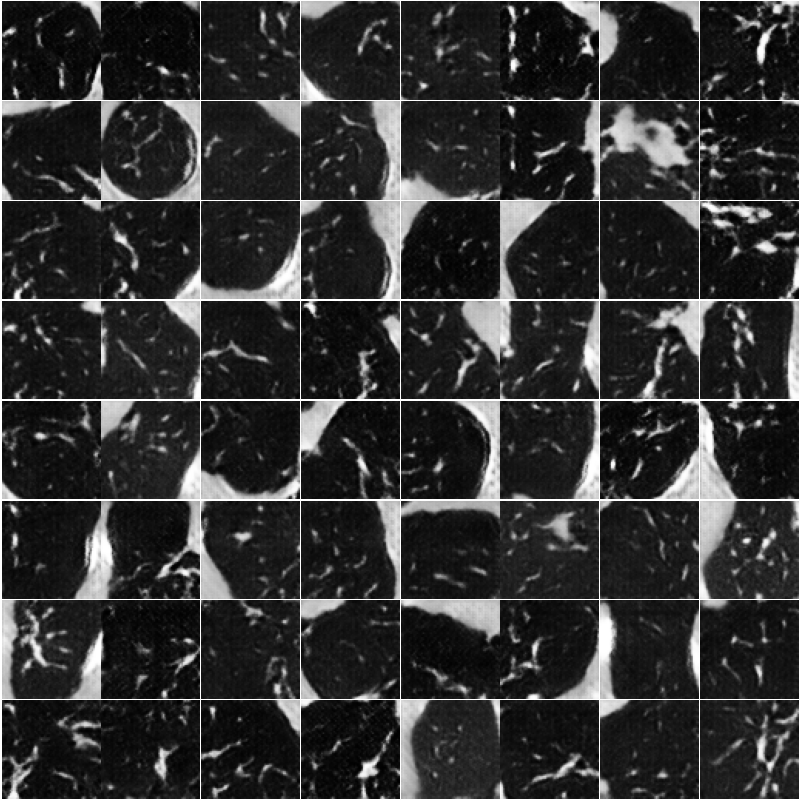

In [34]:
from IPython.display import Image, display

display(Image(filename=str(run_dir / "samples_epoch_020.png")))

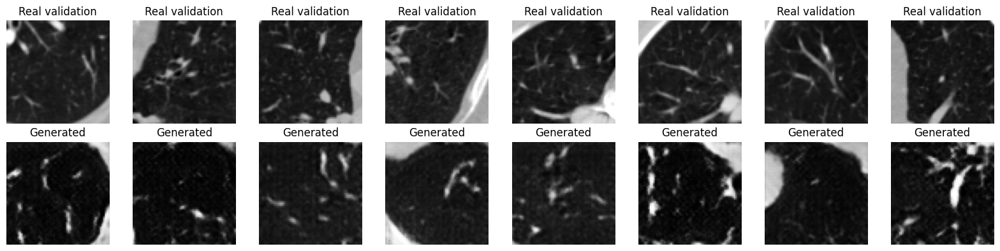

In [35]:
validation_arrays = []
for patient_id in patient_split["validation"]:
    with np.load(validation_dir / f"{patient_id}.npz",
                 allow_pickle=False) as saved:
        validation_arrays.append(saved["patches"])

validation_images = np.concatenate(validation_arrays)
rng = np.random.default_rng(42)
indices = rng.choice(len(validation_images), 8, replace=False)

netG.eval()
with torch.no_grad():
    generated = netG(fixed_noise[:8]).cpu().numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(
        validation_images[indices[i], 0],
        cmap="gray", vmin=-1, vmax=1
    )
    axes[1, i].imshow(
        generated[i, 0], cmap="gray", vmin=-1, vmax=1
    )
    axes[0, i].set_title("Real validation")
    axes[1, i].set_title("Generated")
    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig(run_dir / "validation_vs_generated.png", dpi=150)
plt.show()